vth_curve, v_th = static.run_threshold_voltage(LIB, SUBCKT, i_target=250e-6, v_max=6.0)
fig7, ax7 = plot_curves([vth_curve], f"{TITLE} - Threshold Voltage Sweep", y_log=True)
ax7.axvline(v_th, color="tab:red", linestyle="--", linewidth=1.4)
ax7.annotate(
    f"Vth = {v_th:.3f} V @ 250 uA",
    xy=(v_th, 250e-6), xytext=(12, 18), textcoords="offset points",
    fontsize=12, color="tab:red",
)
plt.show()

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from common.plotting import setup_style, plot_curves
from simulation.testbenches.static_sweep import StaticSweepTestbench
from simulation.testbenches.capacitance import CapacitanceTestbench
from simulation.testbenches.gate_charge import reconstruct_gate_charge, plot_gate_charge

# ── Device under test: switch between supported vendors here ──────────────
# Infineon (MODPEX SPICE3 LEVEL=1)  : irfs7730pbf.spi / irfb_s_sl7730pbf
#   datasheet conditions: Id=100A, Vbus=38V, Vds(cap)=60V, Qgd typ 79 nC
# TI NexFET (PSpice BSIM3v3 LEVEL=7): CSD16412Q5A.lib / CSD16412Q5A
#   datasheet conditions: Id=10A, Vbus=12.5V, Vds(cap)=25V (BV~27), no Qgd cal
DEVICES = {
    "IRFS7730PBF": dict(lib="../SpiceModels/irfs7730pbf.spi",
                        subckt="irfb_s_sl7730pbf",
                        i_load=100.0, v_bus=38.0, qgd_typ=79.0,
                        vgs_max=10.0, vds_cap=60.0),
    "CSD16412Q5A": dict(lib="../SpiceModels/CSD16412Q5A.lib",
                        subckt="CSD16412Q5A",
                        i_load=10.0, v_bus=12.5, qgd_typ=None,
                        vgs_max=4.5, vds_cap=25.0),
}
DEVICE = "CSD16412Q5A"          # <- active device
cfg = DEVICES[DEVICE]

LIB = Path(cfg["lib"]).resolve()
SUBCKT = cfg["subckt"]
TITLE = DEVICE

setup_style()
static = StaticSweepTestbench()

## Study 1 - Output Characteristics (Id vs Vds family)
Datasheet gate curves: Vgs = 4.5 / 5 / 6 / 8 / 10 V.

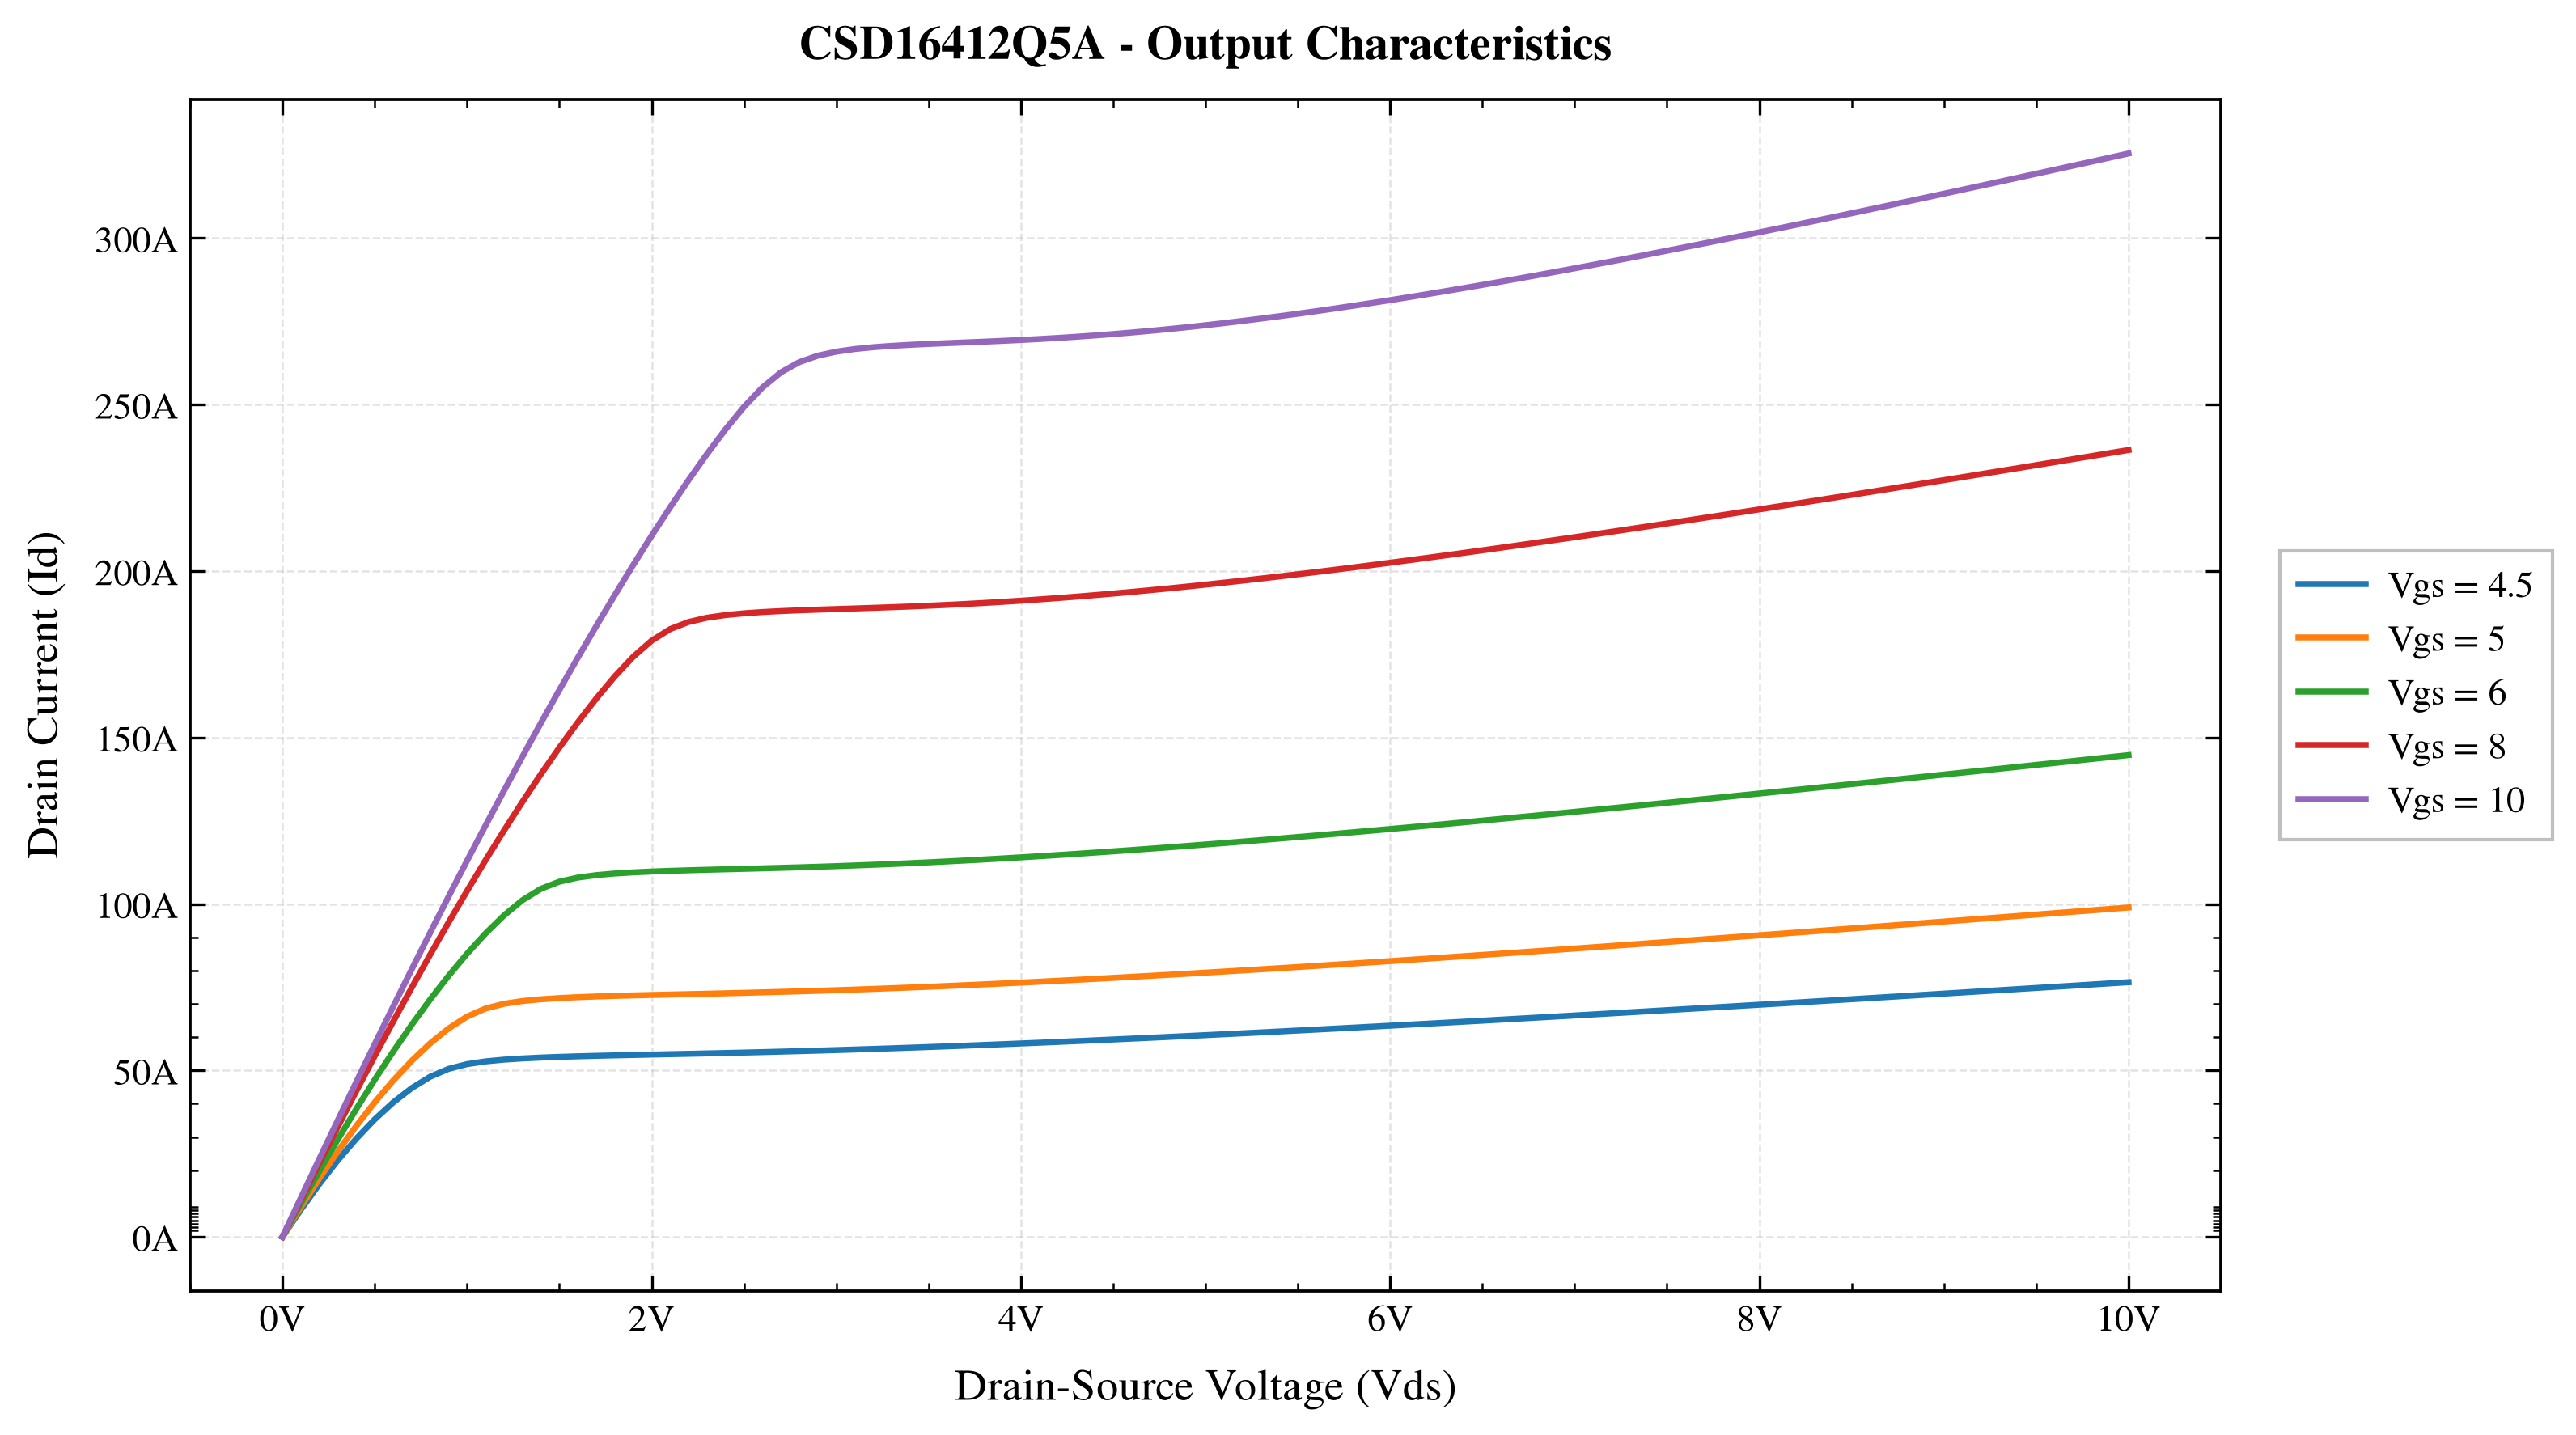

In [2]:
output_curves = static.run_output_characteristics(
    LIB, SUBCKT,
    vgs_list=[4.5, 5.0, 6.0, 8.0, 10.0],
    vds_max=10.0, vds_points=101,
)
fig1, ax1 = plot_curves(output_curves, f"{TITLE} - Output Characteristics")
plt.show()

## Study 2 - Transfer Characteristic (Id vs Vgs at Vds = 10 V)

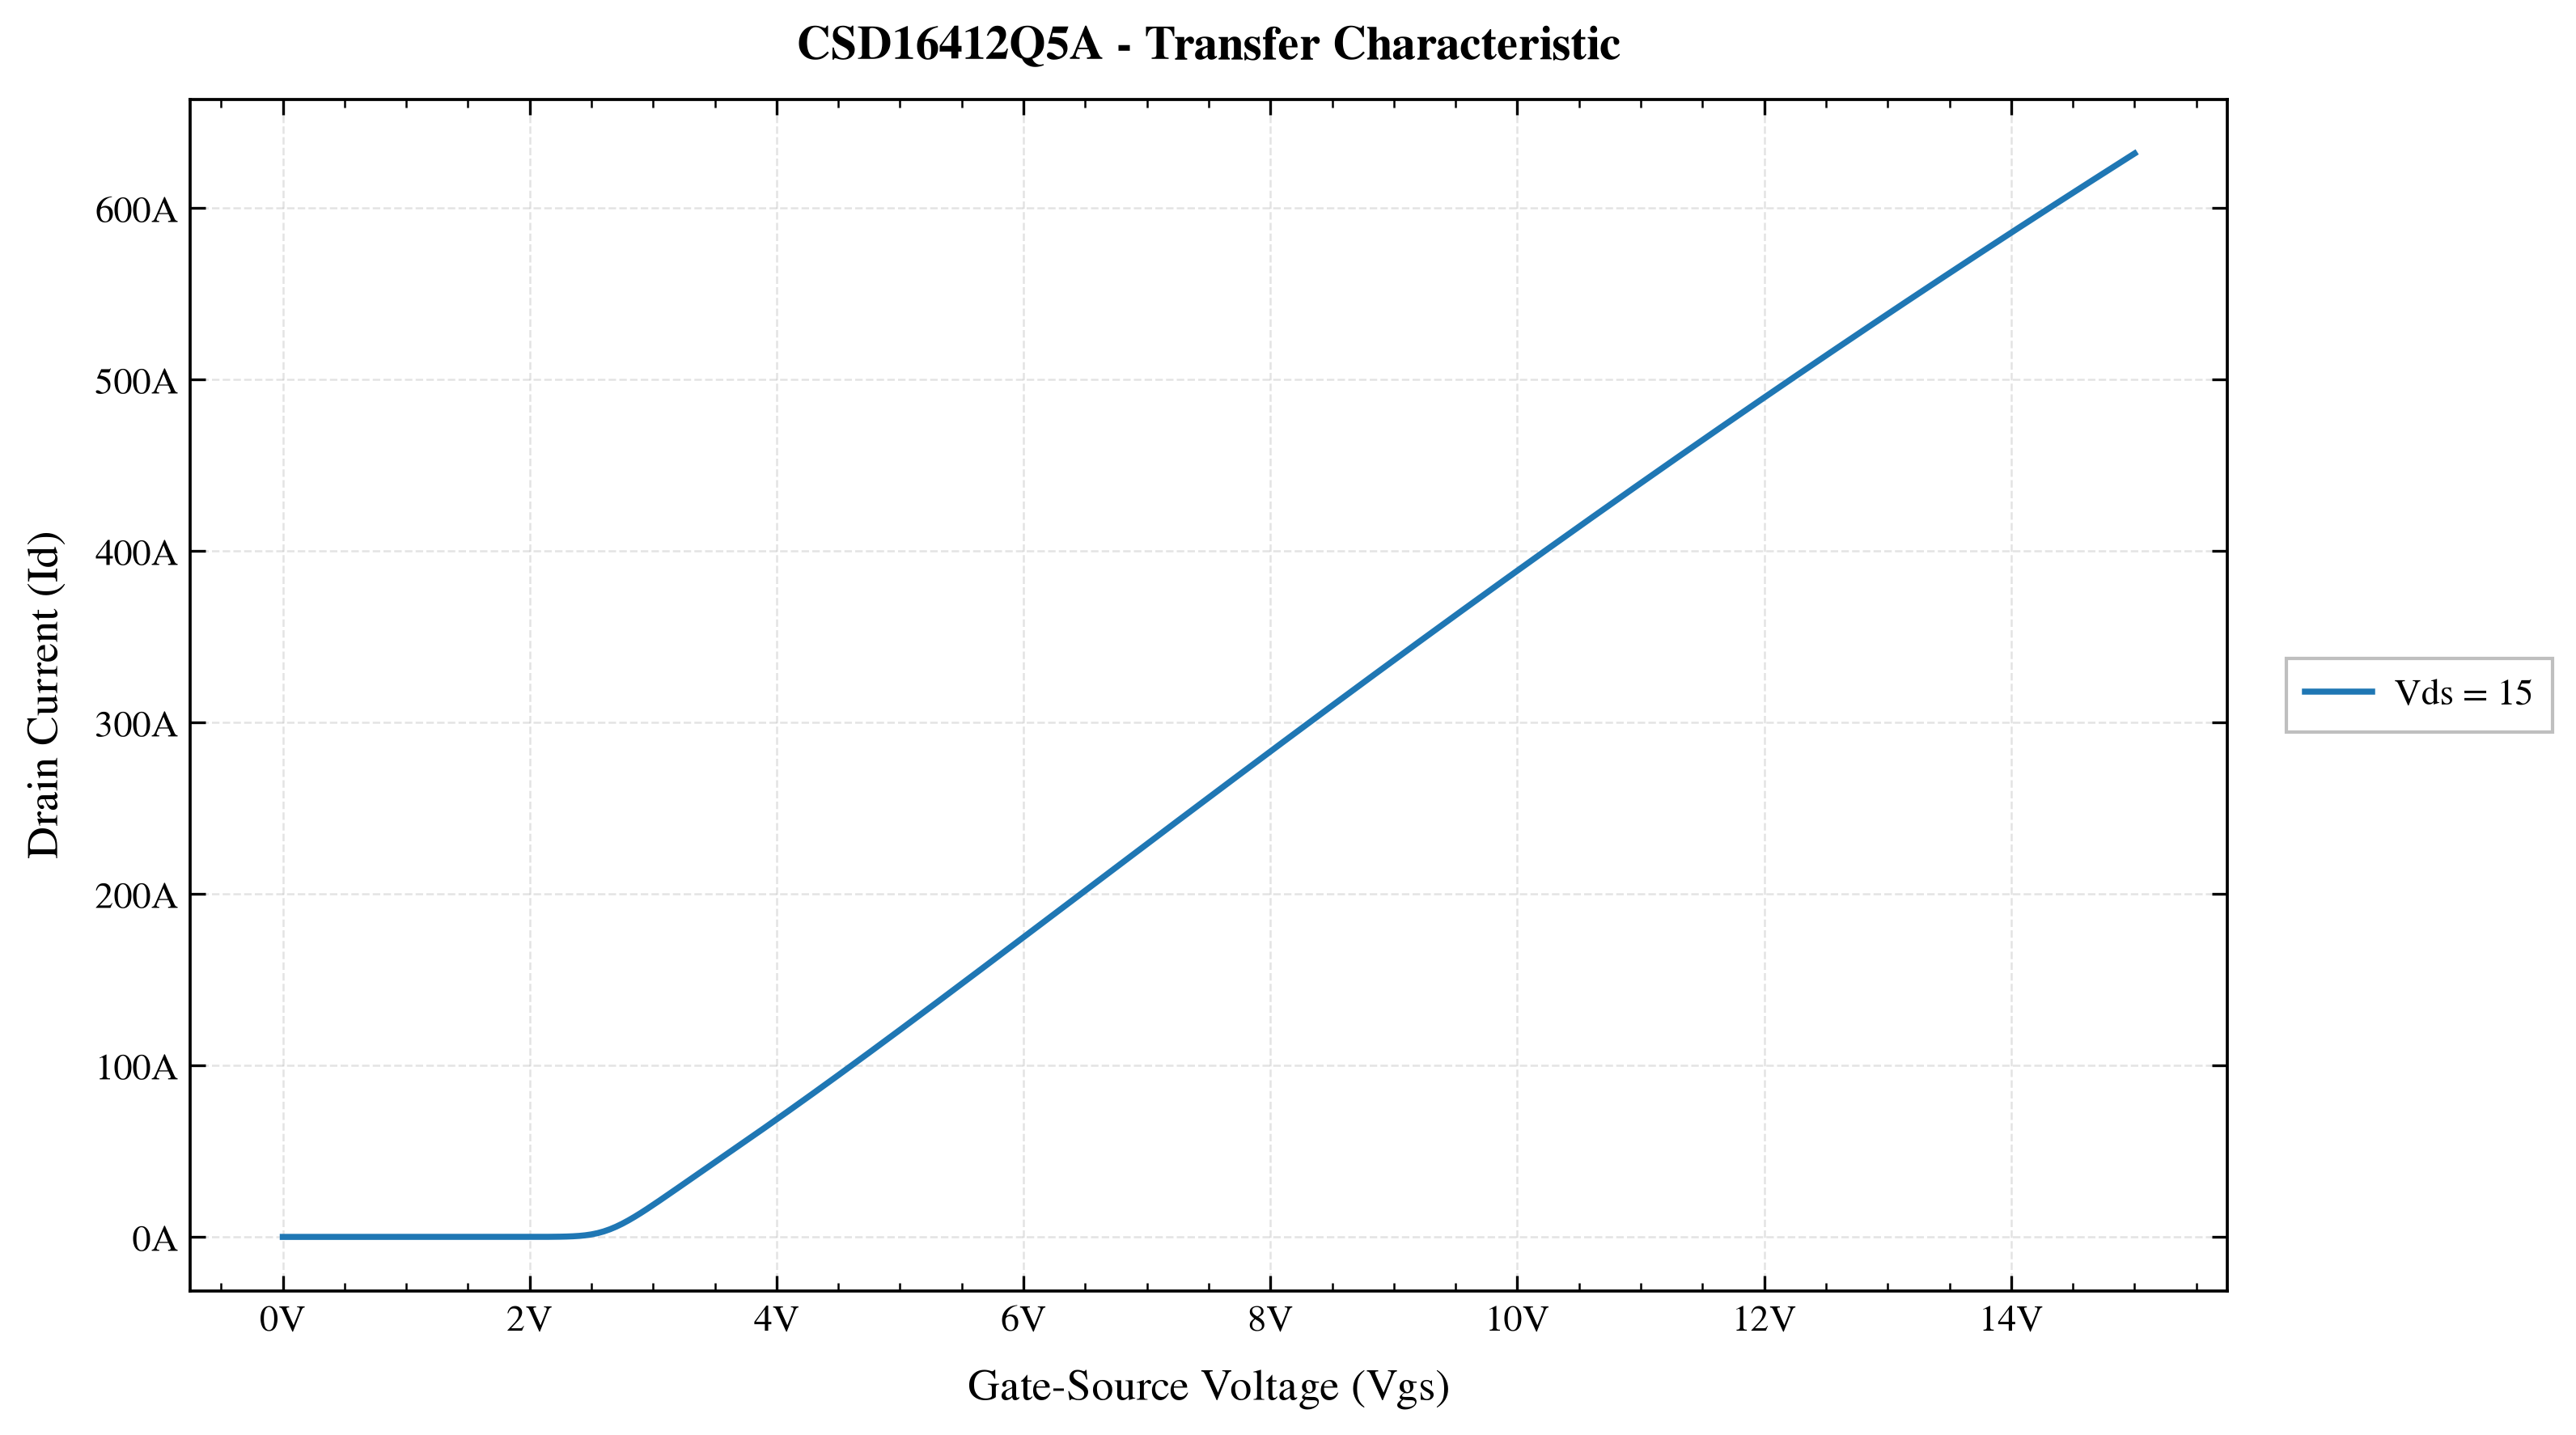

In [3]:
vds_tr = 15.0 if DEVICE == "CSD16412Q5A" else 10.0
transfer_curve = static.run_transfer_characteristics(
    LIB, SUBCKT, vds_fixed=vds_tr, vgs_max=15.0, vgs_points=301,
)
fig2, ax2 = plot_curves([transfer_curve], f"{TITLE} - Transfer Characteristic")
plt.show()

## Study 3 - On-State Resistance (Rds(on) vs Id at Vgs = 10 V)

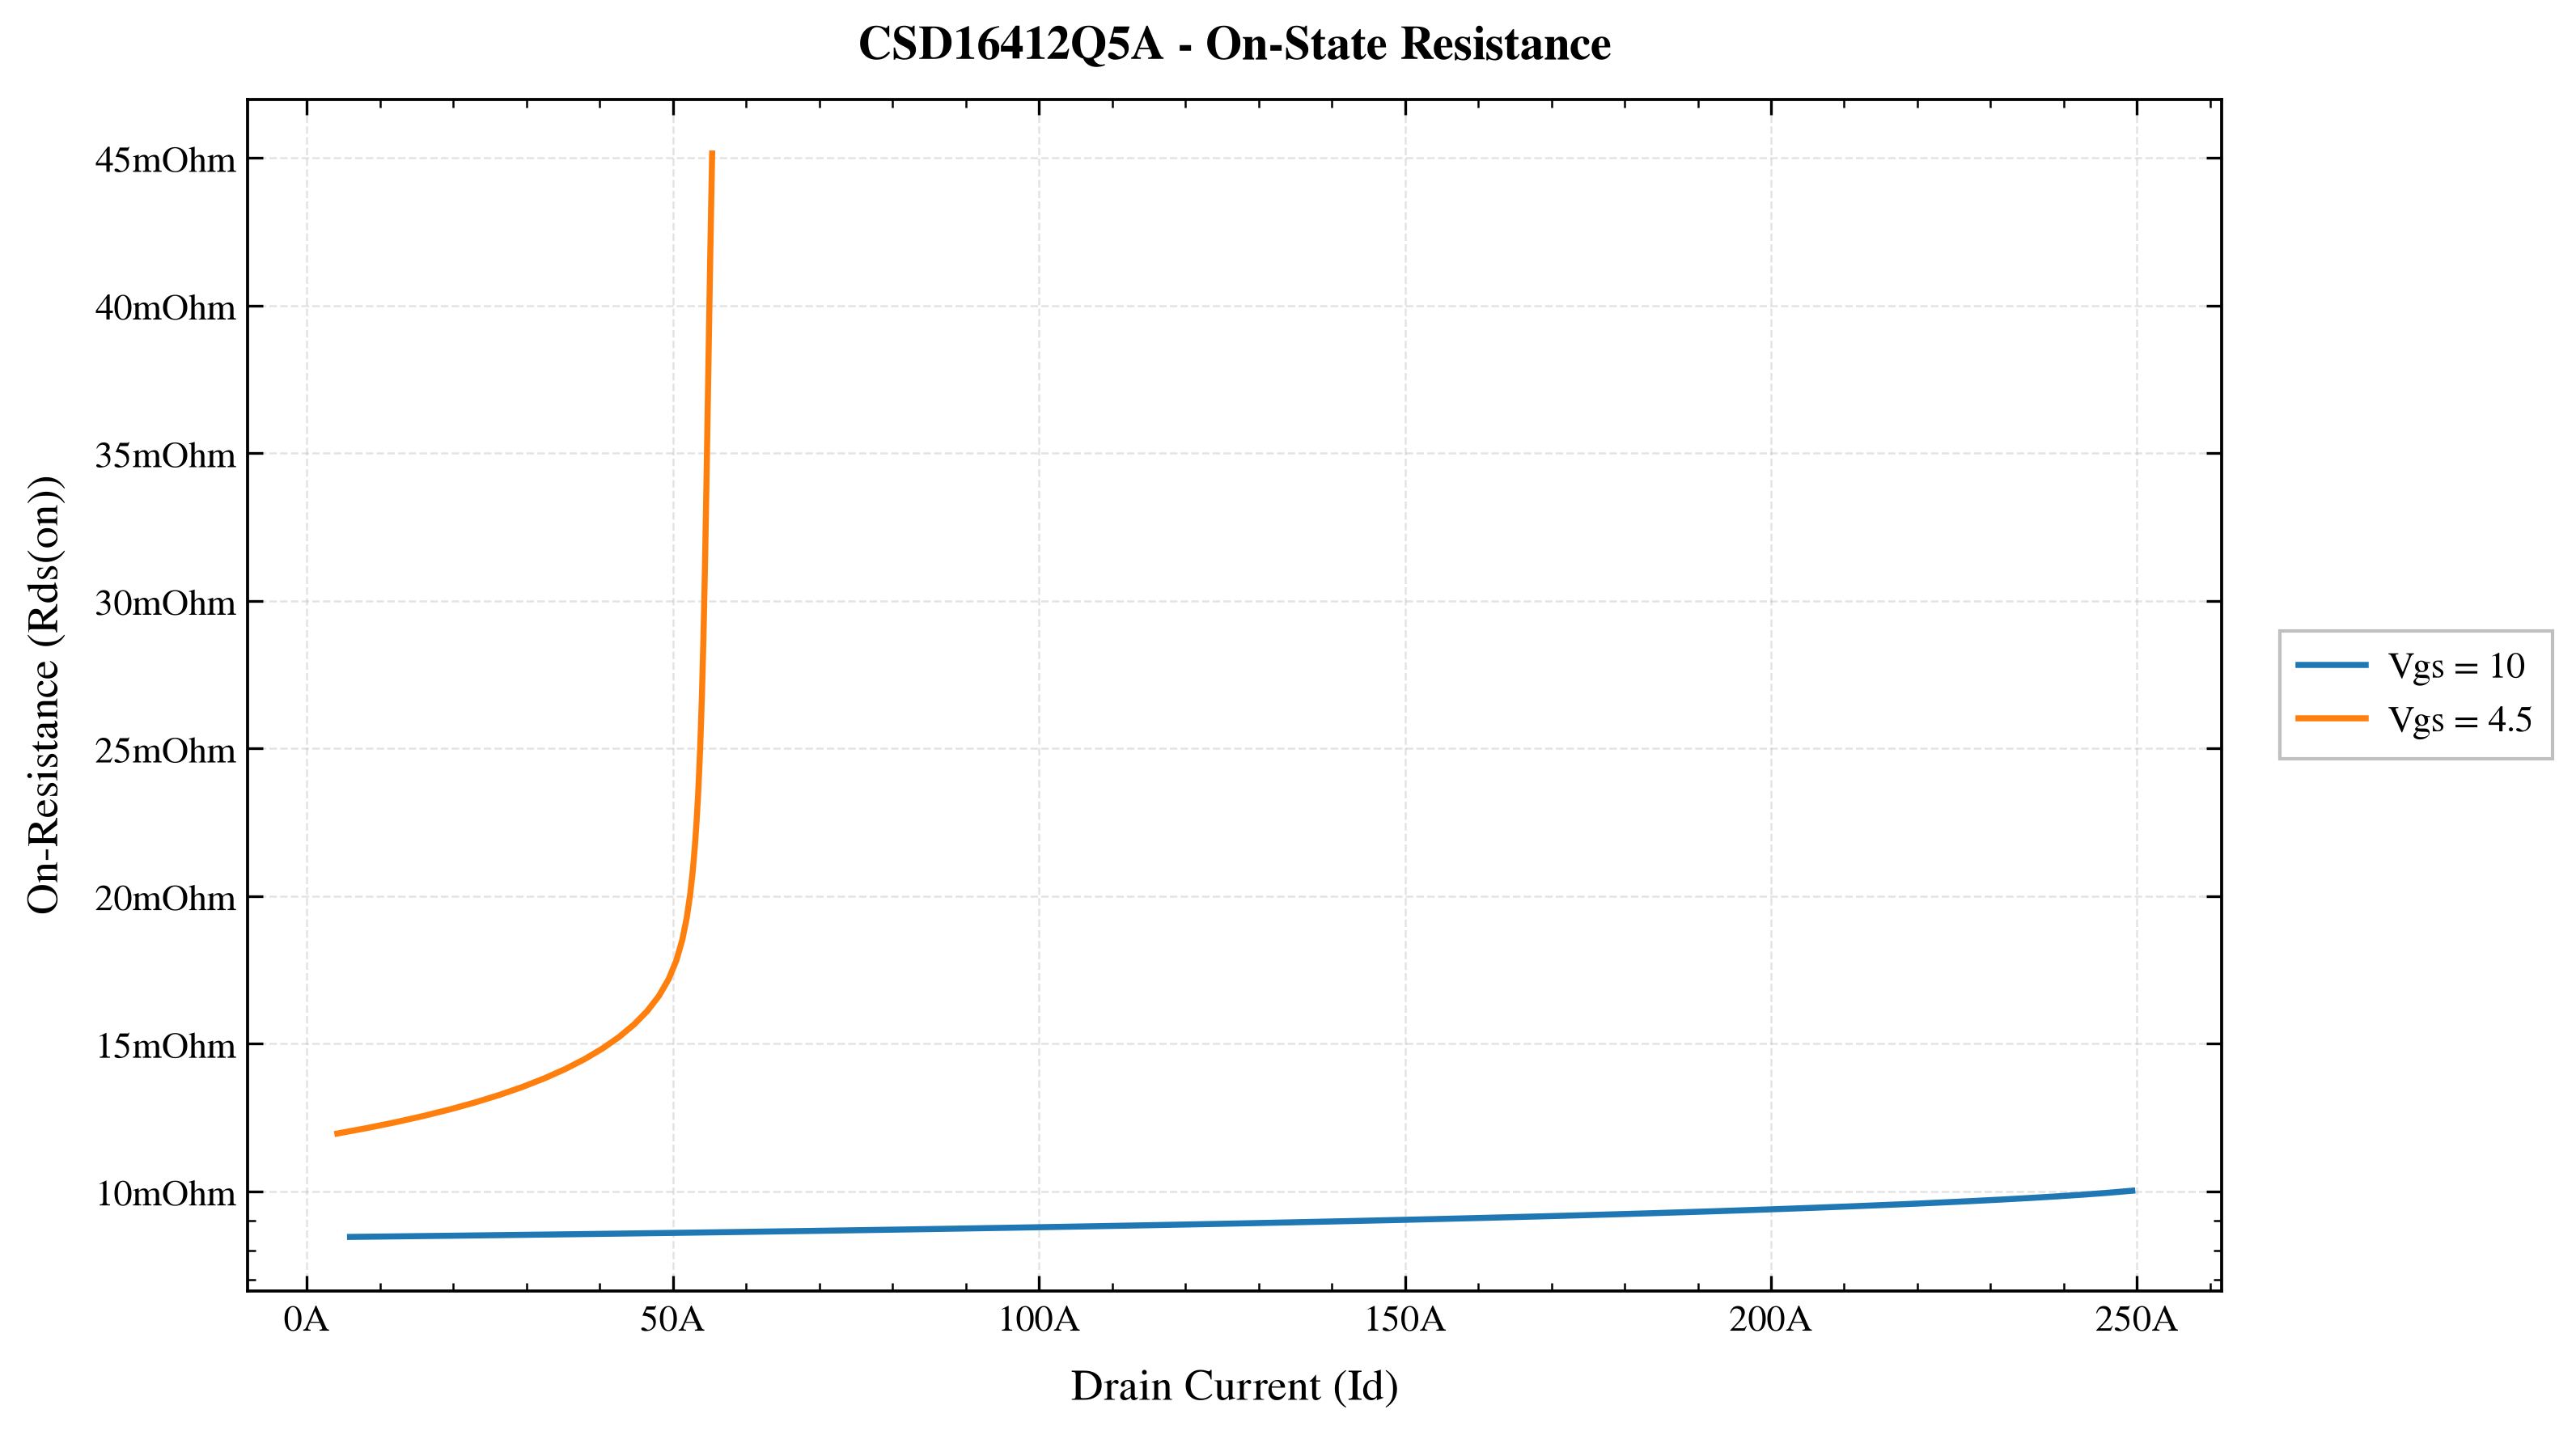

In [4]:
rds_curve = static.run_rds_on(LIB, SUBCKT, vgs=10.0, vds_max=2.5, vds_points=51,
                              min_current=2.0)
rds45_curve = static.run_rds_on(LIB, SUBCKT, vgs=4.5, vds_max=2.5, vds_points=51,
                                min_current=2.0)
fig3, ax3 = plot_curves(
    [rds_curve, rds45_curve], f"{TITLE} - On-State Resistance",
)
plt.show()

## Study 4 - Capacitances vs Vds
Small-signal AC method at 1 MHz; log sweep 0.1-60 V (model breakdown is 75 V).

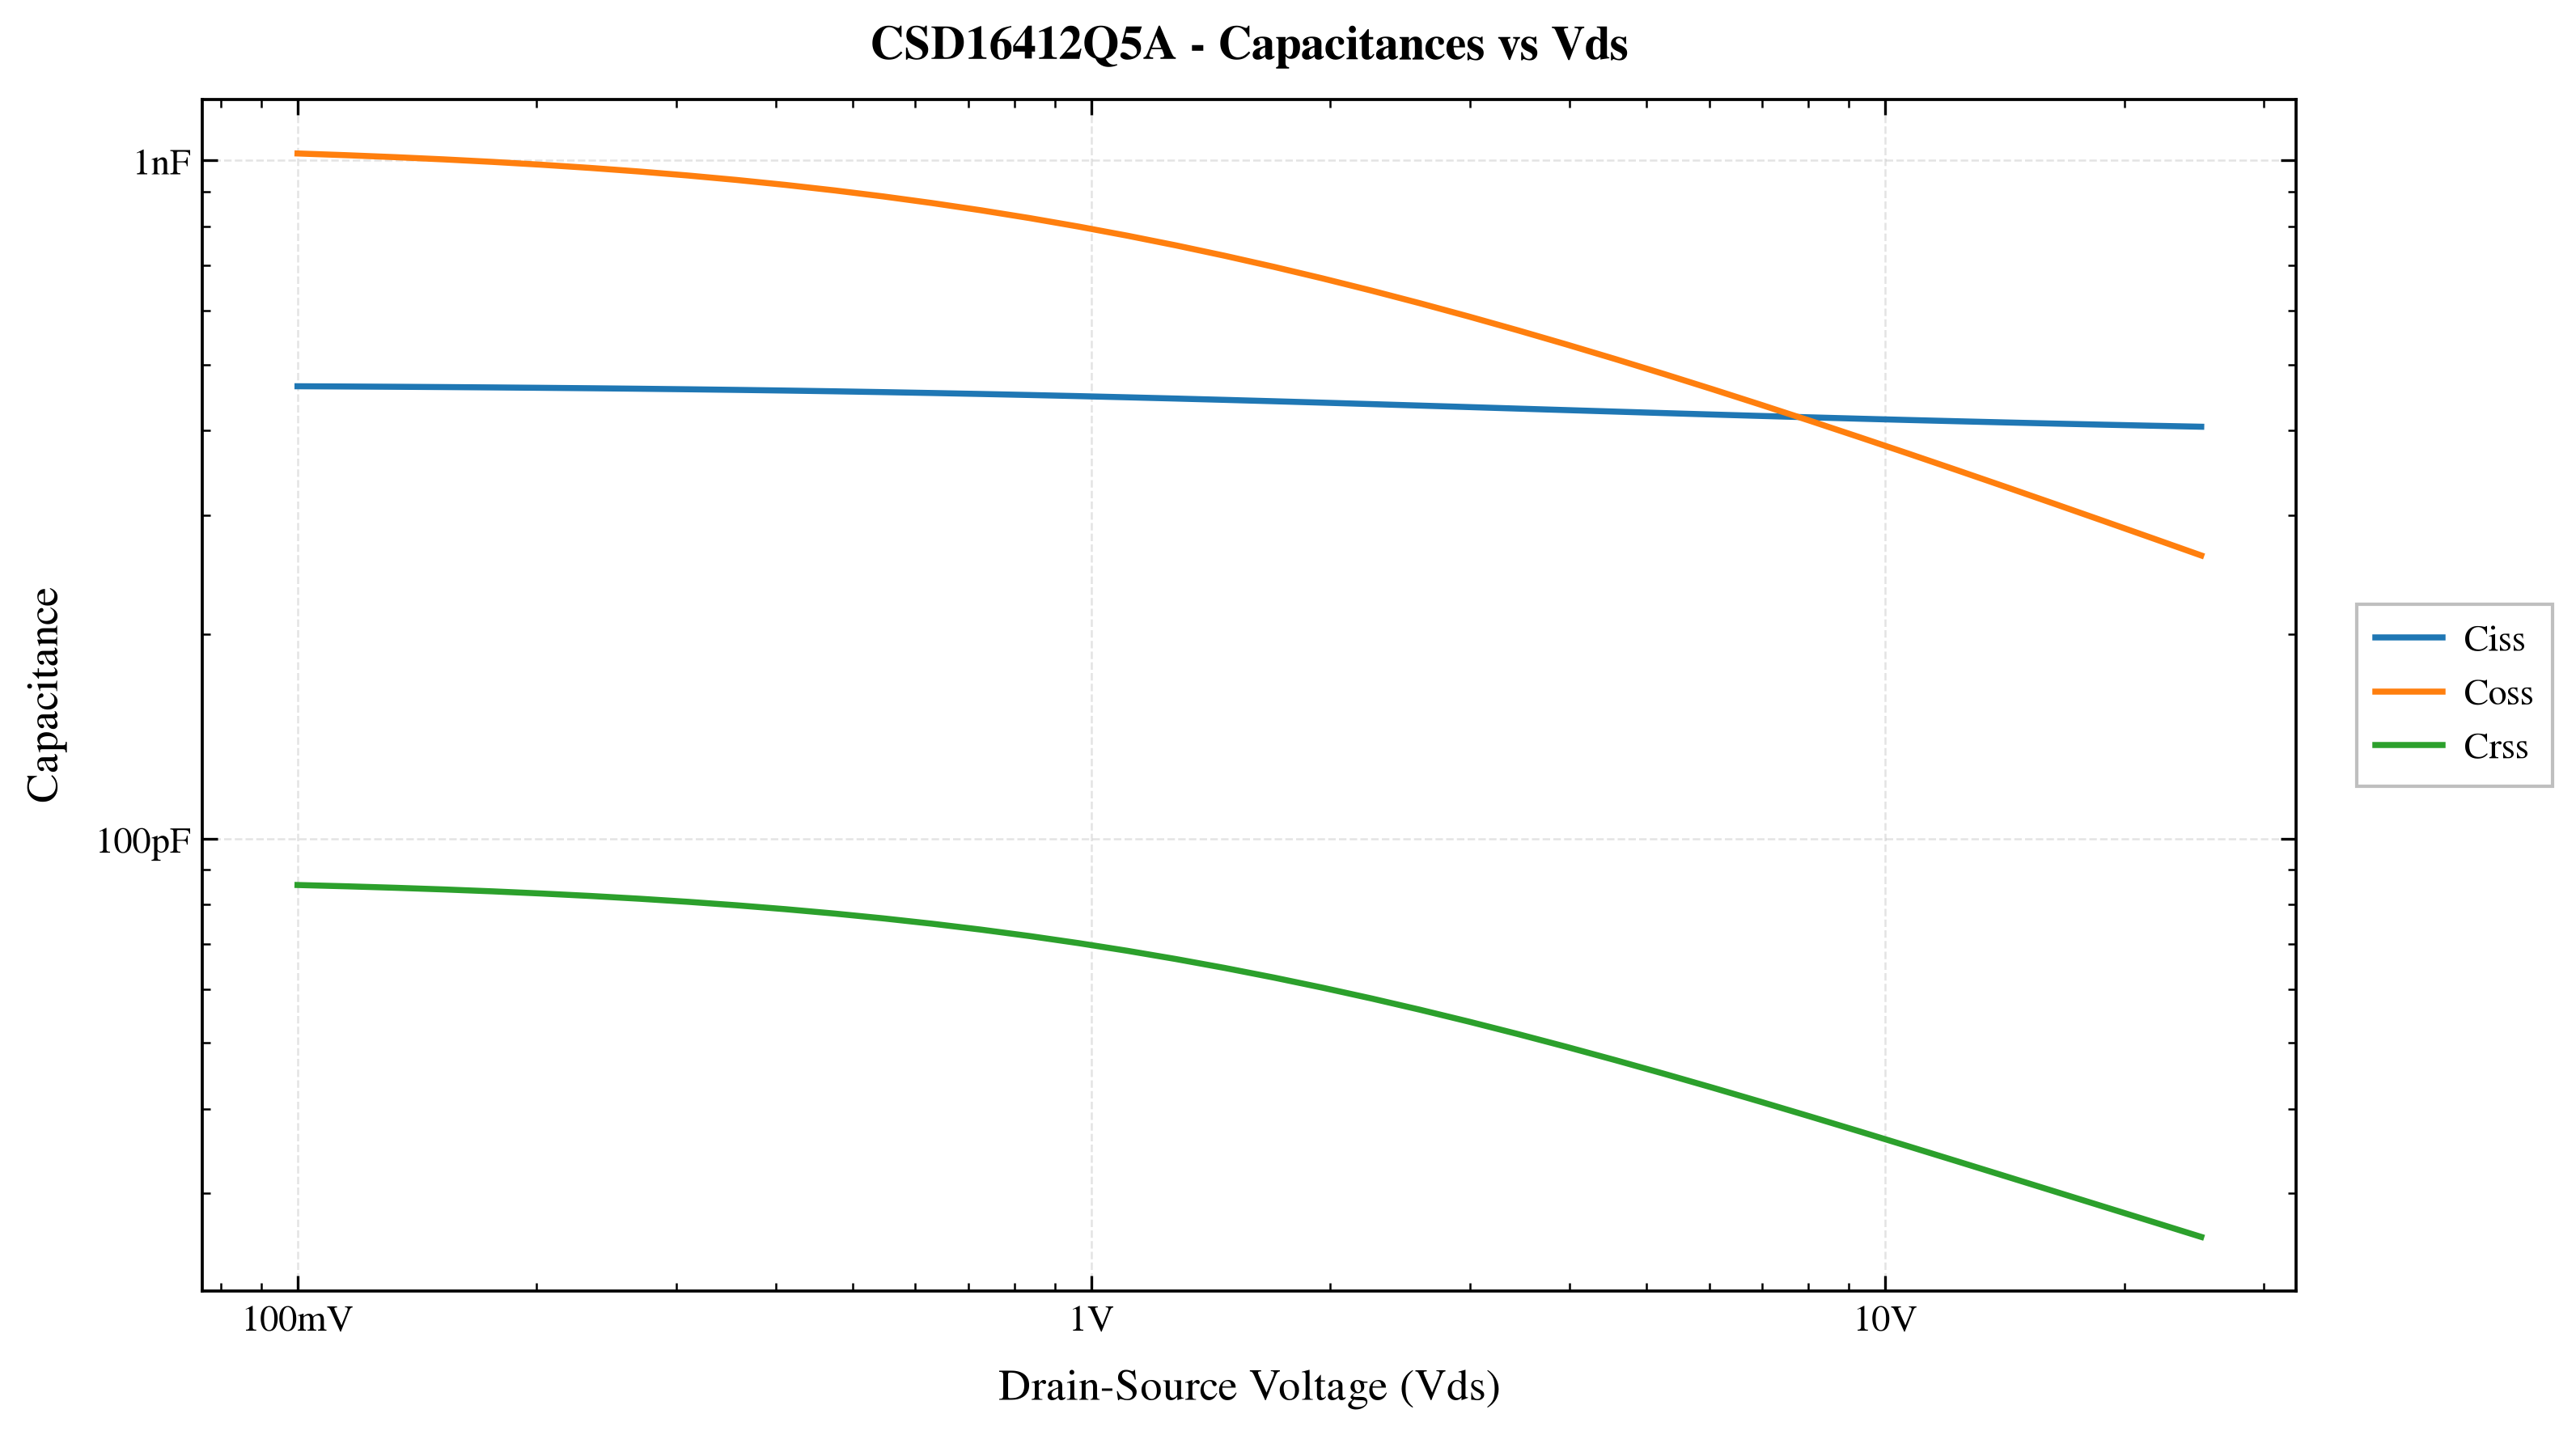

In [5]:
# Sweep ceiling is vendor-aware: the IR MODPEX model breaks down at 75 V, the TI
# NexFET body diode (DBD, BV=27) avalanches near 27 V - beyond that the AC probe
# collapses and Coss explodes (physical breakdown, not a bug).
cap_curves = CapacitanceTestbench().run(LIB, SUBCKT, vds_min=0.1,
                                        vds_max=cfg["vds_cap"], points=40)
fig4, ax4 = plot_curves(
    cap_curves, f"{TITLE} - Capacitances vs Vds", x_log=True, y_log=True,
    y_label="Capacitance",
)
plt.show()

## Study 5 - Gate Charge Curve (quasi-static reconstruction)

Three-segment model built from Study 2 (transfer) and Study 4 (capacitance) data at the
datasheet conditions **Id = 100 A, Vbus = 38 V**:

- **Segment 1 - Qgs**: integrate Ciss(Vds = Vbus) over Vgs from 0 to the plateau voltage
  (where Id(Vgs) crosses the load current).
- **Segment 2 - Qgd (Miller plateau)**: integrate Crss(Vds) over the drain swing Vbus -> ~0 V.
- **Segment 3 - tail**: integrate Ciss(low-Vds) from the plateau to Vgs = 10 V.

Datasheet reference values (typ): Qgs = 55 nC, Qgd = 79 nC, Qg = 271 nC. Deviations trace to the
vendor macromodel's LEVEL=1 core (no subthreshold conduction -> inflated effective threshold)
and its AC-calibrated-but-not-charge-accurate capacitance emulation; see `development-log.md`.


Plateau voltage Vgp : 2.81 V
Qgs                 : 1.16 nC
Qgd (Miller)        : 0.58 nC
Tail charge         : 0.79 nC
Total Qg @ 4.5V     : 2.53 nC


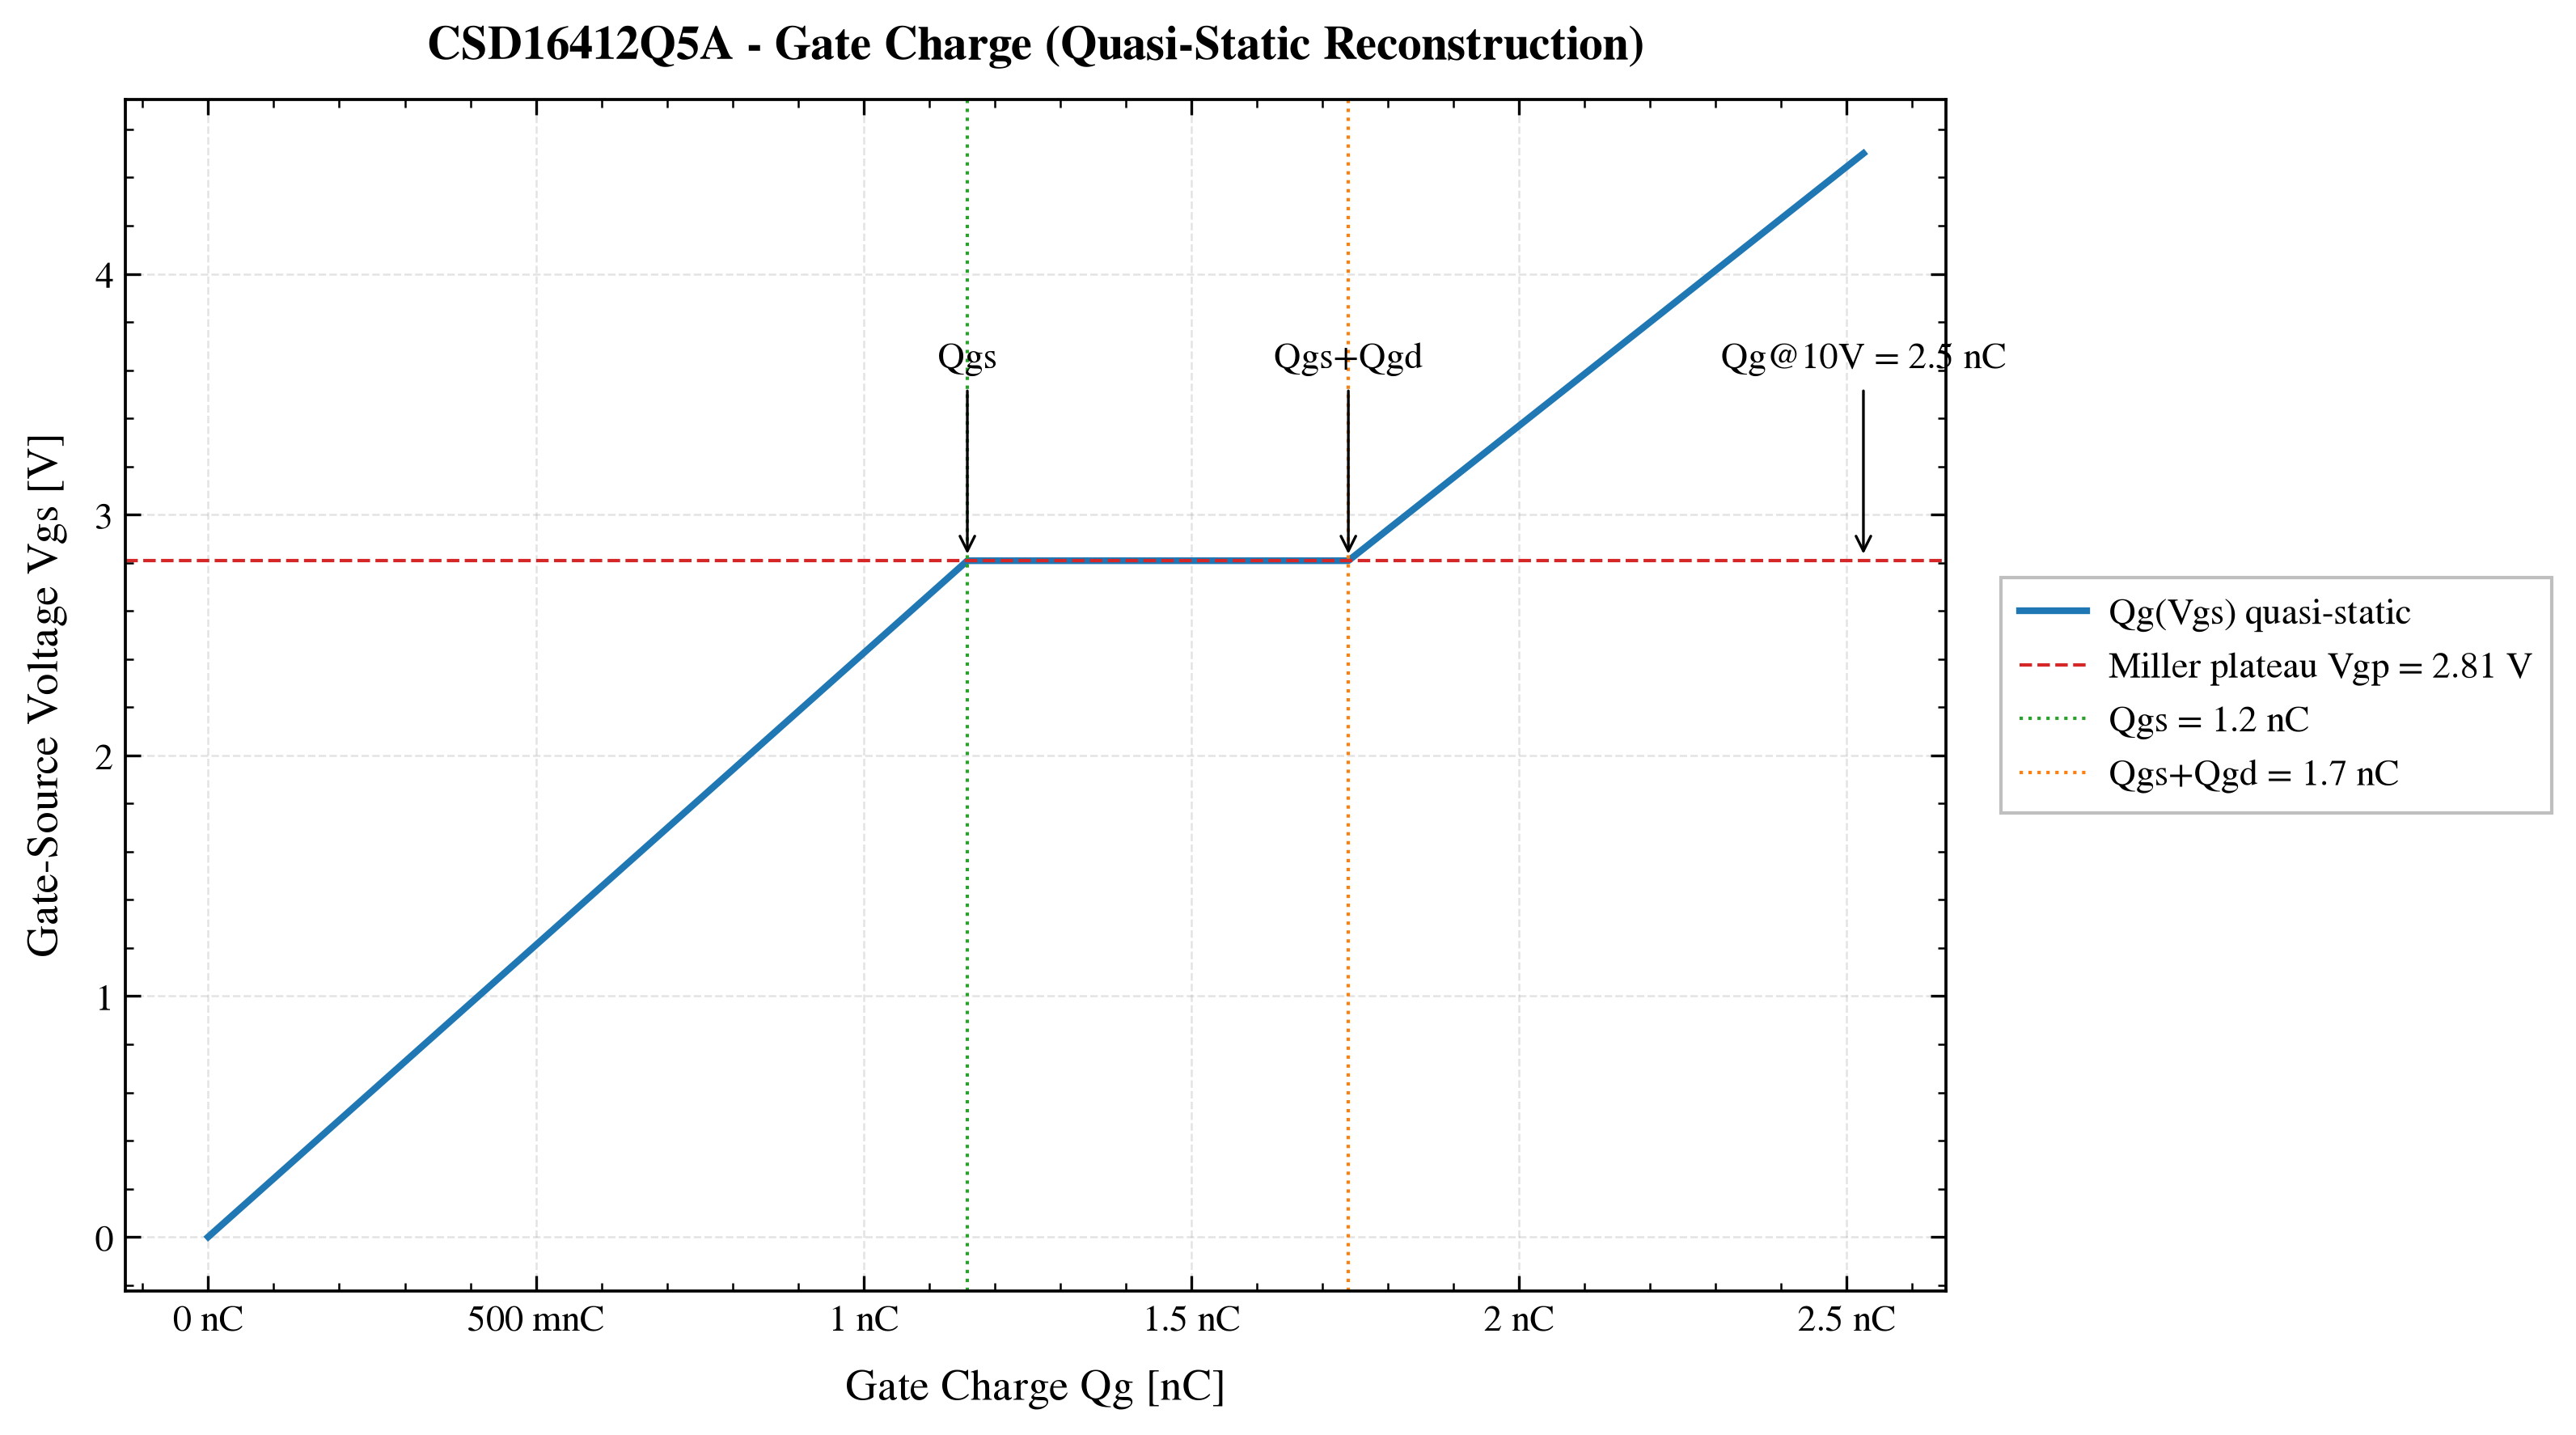

In [6]:
qgd_typ = cfg.get("qgd_typ")   # VM-03 calibration (IR only; TI needs none)
df_qg, bp = reconstruct_gate_charge(
    transfer_curve, cap_curves[0], cap_curves[2],
    v_bus=cfg["v_bus"], i_load=cfg["i_load"], v_gs_max=cfg["vgs_max"],
    v_ds_on=0.05, qgd_cal_nC=qgd_typ,
)
print(f"Plateau voltage Vgp : {bp['v_plateau_V']:.2f} V")
print(f"Qgs                 : {bp['q_gs_nC']:.2f} nC")
print(f"Qgd (Miller)        : {bp['q_gd_nC']:.2f} nC"
      + ("" if qgd_typ is None else f"   (calibrated to datasheet typ {qgd_typ})"))
print(f"Tail charge         : {bp['q_tail_nC']:.2f} nC")
print(f"Total Qg @ {cfg['vgs_max']}V     : {bp['q_total_nC']:.2f} nC")

fig5, ax5 = plot_gate_charge(df_qg, bp)
ax5.set_title(f"{TITLE} - Gate Charge (Quasi-Static Reconstruction)")
plt.show()

## Study 6 - Body Diode Forward Characteristic (gate off)
Voltage-driven, capped at 1 V to stay clear of the diode exponential divergence.

Note: Starting true gmin stepping


Trying gmin =   1.0000E-03 Note: One successful gmin step


Trying gmin =   1.0000E-04 Note: One successful gmin step


Trying gmin =   1.0000E-05 Note: One successful gmin step


Trying gmin =   1.0000E-06 Note: One successful gmin step


Trying gmin =   1.0000E-07 Note: One successful gmin step


... (61 outputs left out)

Trying gmin =   1.0000E-11 Note: One successful gmin step


Trying gmin =   1.0000E-12 Note: One successful gmin step


Trying gmin =   1.0000E-12 Note: One successful gmin step


Note: Dynamic gmin stepping completed


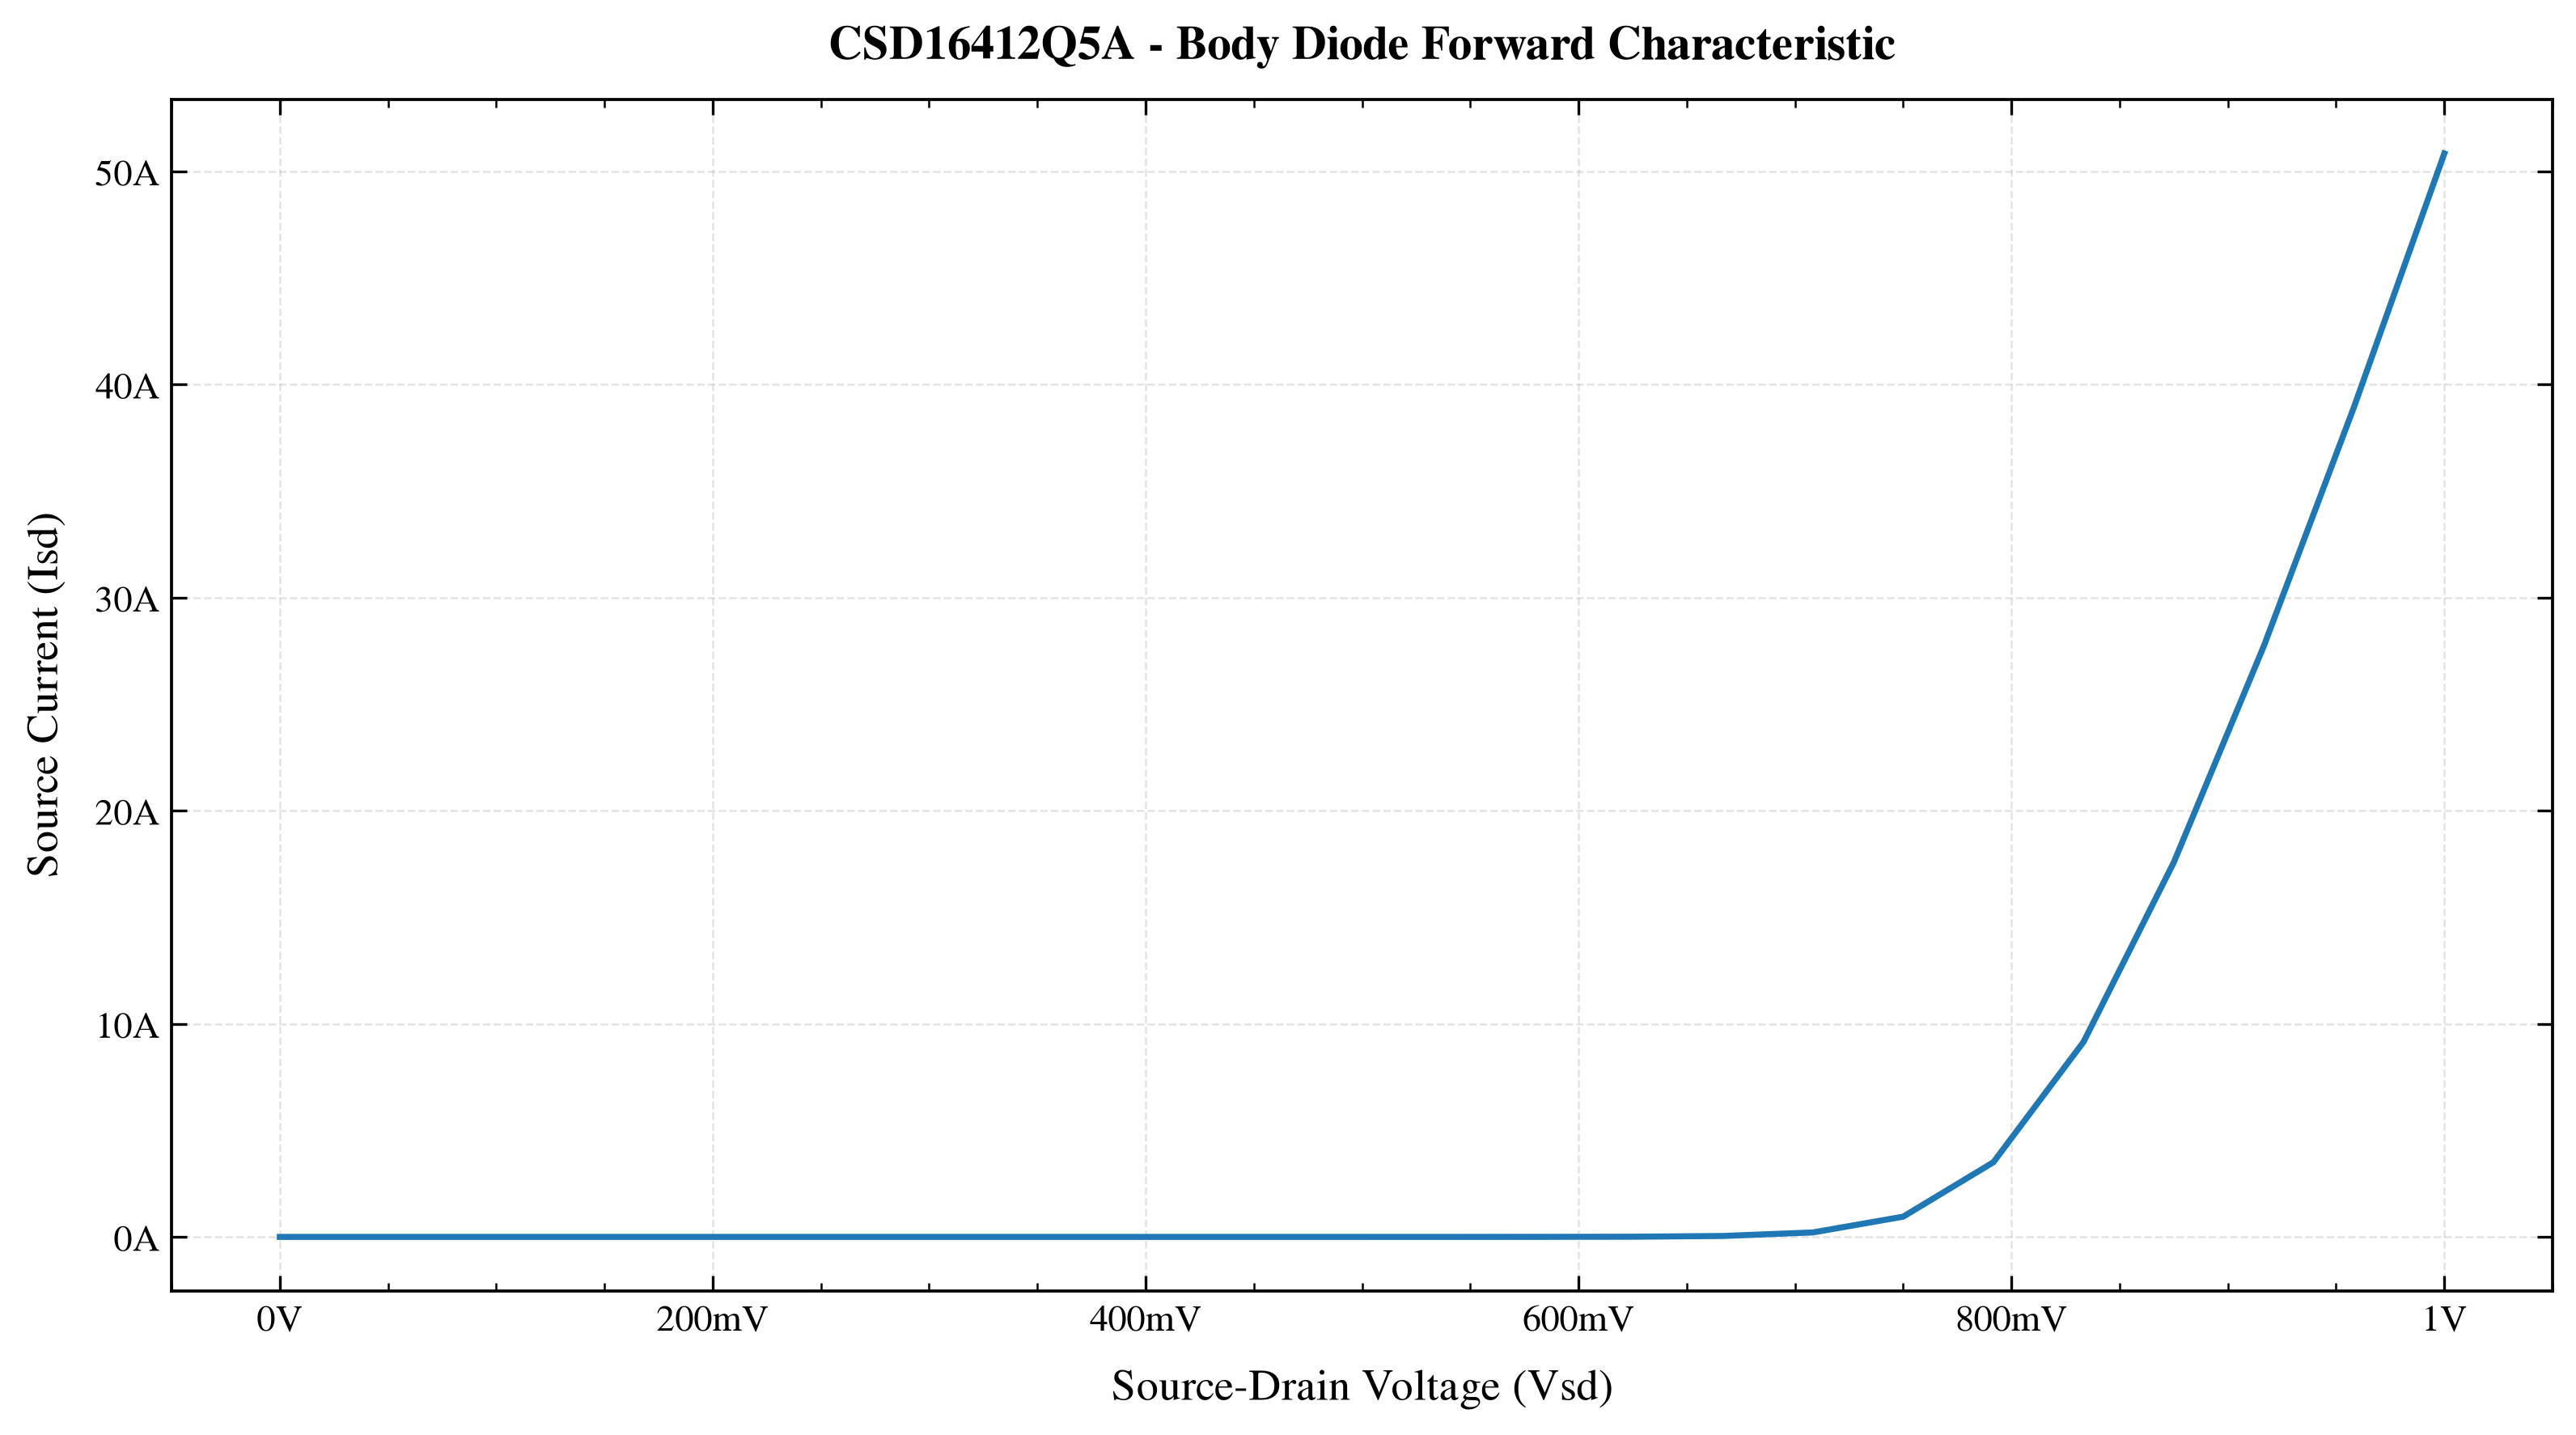

In [7]:
diode_curve = static.run_body_diode(LIB, SUBCKT, vsd_max=1.0, points=51)
fig6, ax6 = plot_curves([diode_curve], f"{TITLE} - Body Diode Forward Characteristic")
plt.show()


## Study 7 - Gate Threshold Voltage (constant-current method)

Datasheet convention: **gate shorted to drain (`Vds = Vgs`)**, sweep, interpolate
`Vgs` at **Id = 250 uA**.

> **Known model limitation:** this vendor macromodel uses a LEVEL=1 MOSFET with a hard
> threshold (no subthreshold conduction). The extracted value reflects the fitted
> `VTO = 4.346 V`, which matches the mid-current transfer characteristic but sits above
> the datasheet spec band **VGS(th) = 2.1-3.7 V** (`VDS = VGS, ID = 250 uA`). The real
> device's subthreshold physics cannot be represented by this LEVEL=1 model file; this is
> a vendor-model artifact, not an extraction error.


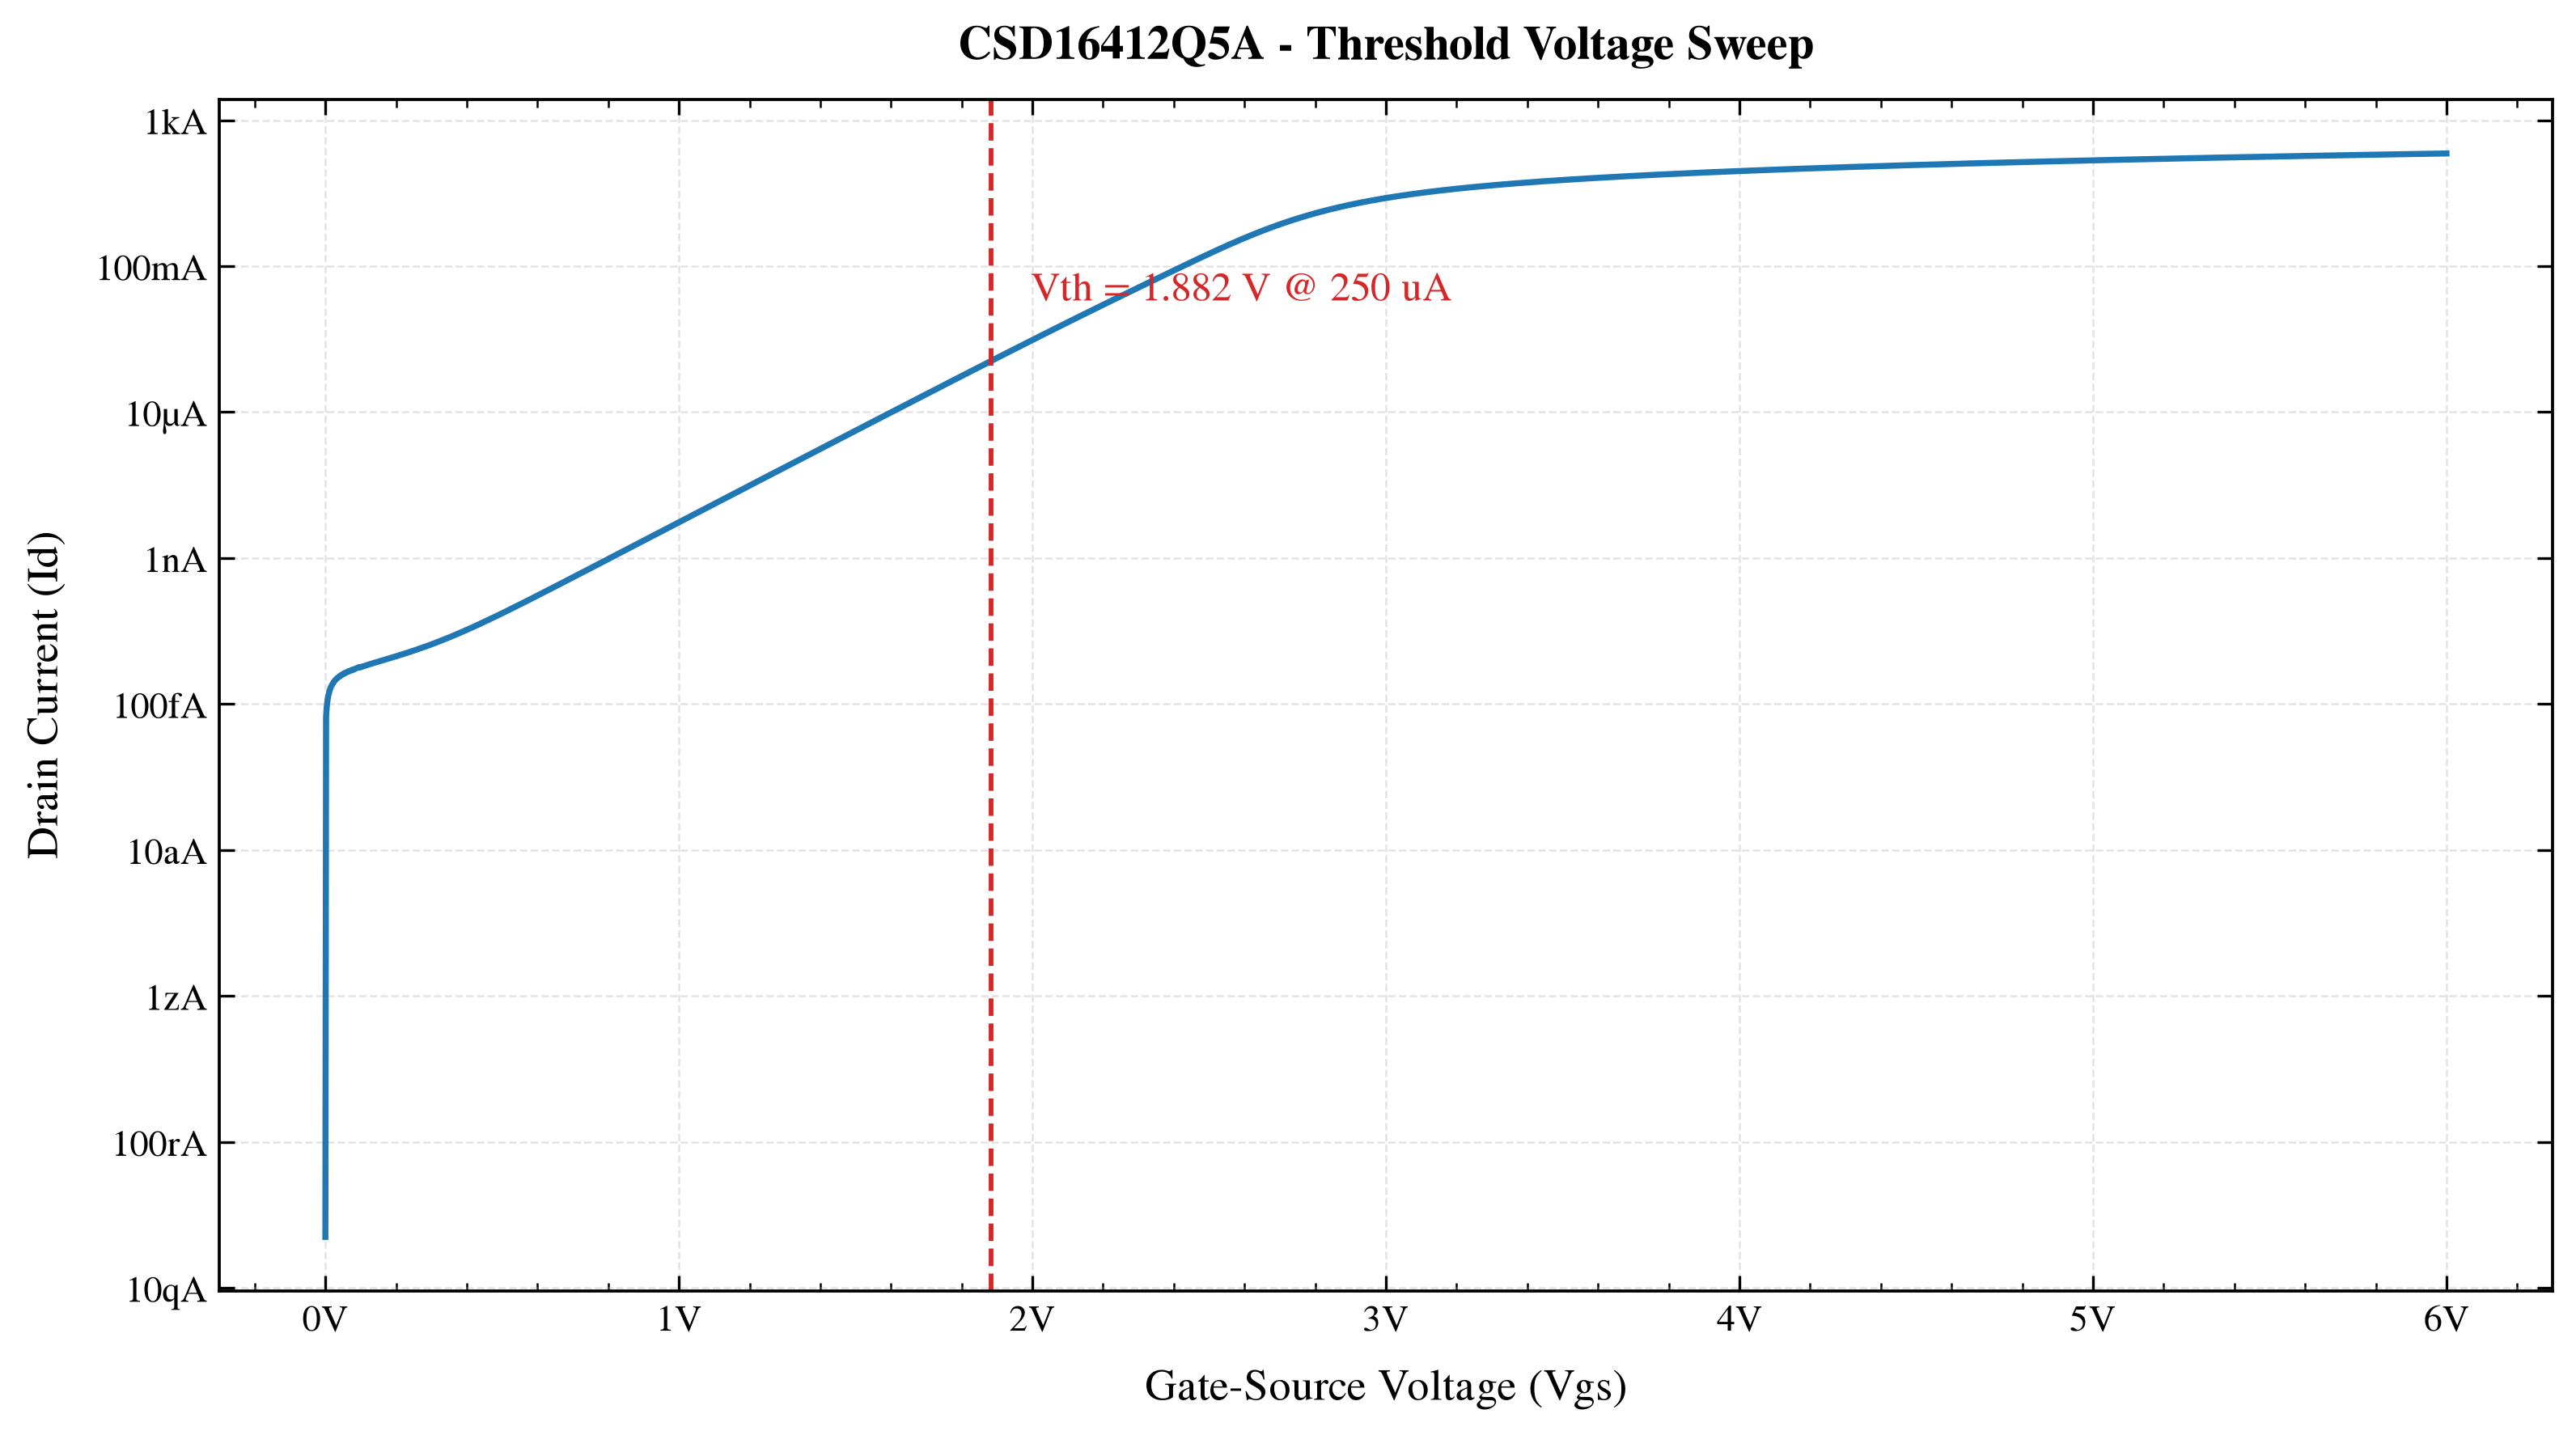

In [8]:
vth_curve, v_th = static.run_threshold_voltage(LIB, SUBCKT, i_target=250e-6, v_max=6.0)
fig7, ax7 = plot_curves([vth_curve], f"{TITLE} - Threshold Voltage Sweep", y_log=True)
ax7.axvline(v_th, color="tab:red", linestyle="--", linewidth=1.4)
ax7.annotate(
    f"Vth = {v_th:.3f} V @ 250 uA",
    xy=(v_th, 250e-6), xytext=(12, 18), textcoords="offset points",
    fontsize=12, color="tab:red",
)
plt.show()

## Extracted Datasheet Figures

In [9]:
rx10, ry10 = rds_curve.to_numpy()
rx45, ry45 = rds45_curve.to_numpy()
id_ref = cfg["i_load"]
cap_ref_v = cfg["v_bus"]

print(f"Rds(on) @ Vgs=10V, Id={id_ref:.0f}A : {np.interp(id_ref, rx10, ry10):.2f} mOhm")
print(f"Rds(on) @ Vgs=4.5V, Id={id_ref:.0f}A : {np.interp(id_ref, rx45, ry45):.2f} mOhm")
print(f"Vgs(th) constant-current  : {v_th:.3f} V")
for c_ in cap_curves:
    print(f"{c_.name} @ Vds={cap_ref_v:.1f}V           : {np.interp(cap_ref_v, c_.x_data, c_.y_data) * 1e12:.0f} pF")
dx, dy = diode_curve.to_numpy()
print(f"Body diode Vsd @ Isd={id_ref:.0f}A  : {np.interp(id_ref, dy, dx) * 1e3:.1f} mV")
print(f"Gate charge Qg @ {cfg['vgs_max']}V    : {bp['q_total_nC']:.2f} nC  (quasi-static reconstruction)")

Rds(on) @ Vgs=10V, Id=10A : 8.47 mOhm
Rds(on) @ Vgs=4.5V, Id=10A : 12.24 mOhm
Vgs(th) constant-current  : 1.882 V
Ciss @ Vds=12.5V           : 412 pF
Coss @ Vds=12.5V           : 348 pF
Crss @ Vds=12.5V           : 33 pF
Body diode Vsd @ Isd=10A  : 837.5 mV
Gate charge Qg @ 4.5V    : 2.53 nC  (quasi-static reconstruction)
